# DUR(의약품안전사용서비스) 금기 데이터 분석 미션

**N기관 의약품 안전 데이터 분석팀** — 성분·병용·금기 데이터를 정형 분석과 텍스트 분석으로 규명하고, 임부금기 1등급 판별 모델을 구성한다.

| 문항 | 내용 | 주요 방법 |
|---|---|---|
| 1 | 병용금기 제품수 상위 100개 성분의 금기 사유 최빈 단어 | 집계, 토큰화, 빈도 분석 |
| 2 | 임부금기 등급별 고시 경과기간 대표값 차이 | 정규성 검정 → Mann-Whitney U |
| 3 | 투여경로(A/B/C) × 금기등급 독립성, 경로별 1등급 비율 | 카이제곱 독립성 검정 |
| 4 | '태아'와 가장 유사한 단어 | Word2Vec |
| 5 | 제품수 최다 성분과 그 성분의 최다 병용금기 성분 | 집계 |
| 6 | 정형+텍스트 기반 임부금기 1등급 판별 | Scikit-learn Pipeline |
| 7 | 상세정보 기반 RNN 판별 모델, `model_dur.h5` 저장 | Keras Bi-LSTM |
| 8 | (선택) 병용금기 사유 토픽 모델링 | LDA (gensim) |

> 데이터: `07_DUR_Data_Zip.zip` (노트북과 같은 폴더)  
> 필요 패키지: `pandas numpy scipy scikit-learn gensim tensorflow matplotlib` (선택: `konlpy` — 설치되어 있으면 형태소 분석을 사용하고, 없으면 규칙 기반 토크나이저로 자동 대체)

## 0. 환경 설정 및 데이터 불러오기

In [1]:
!pip install koreanize-matplotlib

import re
import json
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import koreanize_matplotlib

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 120)

SEED = 42
np.random.seed(SEED)

# 한글 폰트 설정 (환경에 맞는 폰트가 있으면 사용)
# import matplotlib.font_manager as fm
# for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
#     if f in {x.name for x in fm.fontManager.ttflist}:
#         plt.rcParams['font.family'] = f
#         break


plt.rcParams['axes.unicode_minus'] = False

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 68.7 MB/s eta 0:00:00


### 0-1. 원천 데이터 통합
압축파일에는 금기유형별 **품목(제품) 단위** CSV 5개가 들어 있다. 변수 정의서의 분석용 데이터는 **성분 단위**이므로 다음과 같이 통합한다.

| 원천 파일 | 금기유형 | 컬럼 매핑 |
|---|---|---|
| 병용금기 품목리스트 | 병용금기 | 성분명A/성분코드A → 성분명/성분코드, 성분명B/성분코드B → 병용성분명/병용성분코드 |
| 임부금기 품목리스트 | 임부금기 | 금기등급 포함 |
| 연령금기 품목리스트 | 연령금기 | 특정연령·특정연령단위·연령처리조건 포함 |
| 노인주의 품목리스트 | 노인주의 | 공고일자/공고번호 → 고시일자/고시번호, 약품상세정보 → 상세정보 |
| 노인주의(해열진통소염제) | 노인주의_해열진통소염제 | 약품상세정보 → 상세정보 (고시일자 없음) |

- **집계 키**: 금기유형 + 성분코드 + 병용성분코드 + 금기등급 + 연령조건 + 상세정보 + 비고 + 고시번호 + 고시일자
- **제품수** = 키별 품목(행) 수, **성분명·병용성분명** = 그룹 내 최빈 표기
- 결과 검증: 고시일자 2004-01-16 ~ 2025-12-23, 제품수 1 ~ 11,252 → 변수 정의서와 일치

In [7]:
import zipfile, os
from google.colab import drive
drive.mount('/content/drive')
ZIP_PATH = '/content/drive/MyDrive/ai 헬스케어 7기/진료 기록 요약을 위한 자연어 처리(NLP)/07_DUR_Data.Zip.zip'   # ▶ 압축파일 경로
RAW_DIR = 'dur_raw'
os.makedirs(RAW_DIR, exist_ok=True)

# 파일명 키워드 → 저장 이름 (한글 파일명 인코딩 문제를 피하기 위해 영문으로 저장)
NAME_MAP = [('노인주의(', 'old_nsaid'), ('노인주의', 'old'), ('병용금기', 'comb'),
            ('연령금기', 'age'), ('임부금기', 'preg')]

with zipfile.ZipFile(ZIP_PATH) as z:
    for info in z.infolist():
        name = info.filename
        if info.flag_bits & 0x800 == 0:          # UTF-8 플래그가 없으면 cp437 → cp949 복원
            try:
                name = name.encode('cp437').decode('cp949')
            except (UnicodeEncodeError, UnicodeDecodeError):
                pass
        for kw, short in NAME_MAP:
            if kw in name:
                with open(f'{RAW_DIR}/{short}.csv', 'wb') as f:
                    f.write(z.read(info))
                print(f'{short:10s} ← {name}')
                break

Mounted at /content/drive
old        ← 의약품안전사용서비스(DUR)_노인주의 품목리스트 2026.6.csv
old_nsaid  ← 의약품안전사용서비스(DUR)_노인주의(해열진통소염제) 품목리스트 2026.6.csv
comb       ← 의약품안전사용서비스(DUR)_병용금기 품목리스트 2026.6.csv
age        ← 의약품안전사용서비스(DUR)_연령금기 품목리스트 2026.6.csv
preg       ← 의약품안전사용서비스(DUR)_임부금기 품목리스트 2026.6.csv


In [8]:
def read_csv_kr(path, **kw):
    for enc in ['cp949', 'utf-8-sig', 'utf-8']:
        try:
            return pd.read_csv(path, encoding=enc, **kw)
        except UnicodeDecodeError:
            continue
    raise ValueError(path)

# 병용금기는 약 87만 행(250MB) → 필요한 컬럼만 로드
comb = read_csv_kr(f'{RAW_DIR}/comb.csv',
                   usecols=['성분명A', '성분코드A', '성분명B', '성분코드B', '고시번호', '고시일자', '상세정보', '비고'])
comb = comb.rename(columns={'성분코드A': '성분코드', '성분명A': '성분명',
                            '성분코드B': '병용성분코드', '성분명B': '병용성분명'})
comb['금기유형'] = '병용금기'

preg = read_csv_kr(f'{RAW_DIR}/preg.csv').dropna(subset=['성분코드'])   # 전체 결측 행 제거
preg['금기유형'] = '임부금기'

age = read_csv_kr(f'{RAW_DIR}/age.csv')
age['금기유형'] = '연령금기'

old = read_csv_kr(f'{RAW_DIR}/old.csv').rename(
    columns={'공고일자': '고시일자', '공고번호': '고시번호', '약품상세정보': '상세정보'})
old['금기유형'] = '노인주의'

nsaid = read_csv_kr(f'{RAW_DIR}/old_nsaid.csv').rename(columns={'약품상세정보': '상세정보'})
nsaid['금기유형'] = '노인주의_해열진통소염제'

for nm, d in [('병용금기', comb), ('임부금기', preg), ('연령금기', age), ('노인주의', old), ('노인주의_해열진통소염제', nsaid)]:
    print(f'{nm:14s} 품목 행 수: {len(d):>8,}')

병용금기           품목 행 수:  873,147
임부금기           품목 행 수:   18,671
연령금기           품목 행 수:    2,866
노인주의           품목 행 수:      557
노인주의_해열진통소염제   품목 행 수:    1,034


In [11]:
import pandas as pd

COLS = [
    '금기유형',
    '성분코드',
    '성분명',
    '병용성분코드',
    '병용성분명',
    '금기등급',
    '특정연령',
    '특정연령단위',
    '연령처리조건',
    '상세정보',
    '비고',
    '고시번호',
    '고시일자',
]
KEYS = [c for c in COLS if c not in ('성분명', '병용성분명')]

# 이전 셀의 변수가 남아있는지 확인 후 로드
if 'comb' not in globals():
  comb = read_csv_kr(
      f'{RAW_DIR}/comb.csv',
      usecols=[
          '성분명A',
          '성분코드A',
          '성분명B',
          '성분코드B',
          '고시번호',
          '고시일자',
          '상세정보',
          '비고',
      ],
  ).rename(
      columns={
          '성분코드A': '성분코드',
          '성분명A': '성분명',
          '성분코드B': '병용성분코드',
          '성분명B': '병용성분명',
      }
  )
  comb['금기유형'] = '병용금기'
  preg = read_csv_kr(f'{RAW_DIR}/preg.csv').dropna(subset=['성분코드'])
  preg['금기유형'] = '임부금기'
  age = read_csv_kr(f'{RAW_DIR}/age.csv')
  age['금기유형'] = '연령금기'
  old = read_csv_kr(f'{RAW_DIR}/old.csv').rename(
      columns={'공고일자': '고시일자', '공고번호': '고시번호', '약품상세정보': '상세정보'}
  )
  old['금기유형'] = '노인주의'
  nsaid = read_csv_kr(f'{RAW_DIR}/old_nsaid.csv').rename(
      columns={'약품상세정보': '상세정보'}
  )
  nsaid['금기유형'] = '노인주의_해열진통소염제'

raw_all = pd.concat(
    [d.reindex(columns=COLS) for d in [comb, preg, age, old, nsaid]],
    ignore_index=True,
)
raw_all['금기등급'] = raw_all['금기등급'].astype('string')

# 제품수 = 동일 금기 항목(키)에 속한 품목 수
df_raw = (
    raw_all.groupby(KEYS, dropna=False).size().rename('제품수').reset_index()
)

# 성분명·병용성분명 = 그룹 내 가장 많이 쓰인 표기
for nm in ['성분명', '병용성분명']:
  rep = (
      raw_all.groupby(KEYS + [nm], dropna=False)
      .size()
      .rename('_n')
      .reset_index()
      .sort_values('_n', ascending=False)
      .drop_duplicates(KEYS)[KEYS + [nm]]
  )
  df_raw = df_raw.merge(rep, on=KEYS, how='left')

df_raw = df_raw[COLS + ['제품수']]

print('통합 데이터 크기:', df_raw.shape)

# 고시일자 최소/최대값 확인 (결측치 제외 및 문자열 변환 처리)
valid_dates = df_raw['고시일자'].dropna().astype(str)
if not valid_dates.empty:
  print('고시일자 범위:', valid_dates.min(), '~', valid_dates.max())

print('제품수 범위:', df_raw['제품수'].min(), '~', f"{df_raw['제품수'].max():,}")

df_raw.to_csv('dur_integrated.csv', index=False, encoding='utf-8-sig')
df_raw.head()

통합 데이터 크기: (28501, 14)
고시일자 범위: 2004-01-16 ~ 2025-12-23
제품수 범위: 1 ~ 11,252


,금기유형,성분코드,성분명,병용성분코드,병용성분명,금기등급,특정연령,특정연령단위,연령처리조건,상세정보,비고,고시번호,고시일자,제품수
0,노인주의,107501ATB,amitriptyline hydrochloride,NaN,NaN,<NA>,NaN,NaN,NaN,"노인에서의 삼환계 항우울제 사용은 기립성 저혈압, 비틀거림, 항콜린 부작용(인지기능 저하, 섬망 악화, 구갈, 배뇨곤란, 변비 등)이 나타나기 쉬우므로 사용을 추천하지 않으며, 반드시 필요한 경우에만 저용량으...",NaN,20170079.0,2017-02-16,3
1,노인주의,107502ATB,amitriptyline hydrochloride,NaN,NaN,<NA>,NaN,NaN,NaN,"노인에서의 삼환계 항우울제 사용은 기립성 저혈압, 비틀거림, 항콜린 부작용(인지기능 저하, 섬망 악화, 구갈, 배뇨곤란, 변비 등)이 나타나기 쉬우므로 사용을 추천하지 않으며, 반드시 필요한 경우에만 저용량으...",NaN,20170079.0,2017-02-16,1
2,노인주의,107504ATB,amitriptyline hydrochloride,NaN,NaN,<NA>,NaN,NaN,NaN,"노인에서의 삼환계 항우울제 사용은 기립성 저혈압, 비틀거림, 항콜린 부작용(인지기능 저하, 섬망 악화, 구갈, 배뇨곤란, 변비 등)이 나타나기 쉬우므로 사용을 추천하지 않으며, 반드시 필요한 경우에만 저용량으...",NaN,20170079.0,2017-02-16,1
3,노인주의,116001ATB,benztropine mesylate,NaN,NaN,<NA>,NaN,NaN,NaN,항콜린성 작용이 있는 약제와의 병용으로 인해 항콜린 부작용이 증가하므로 동시 사용을 추천하지 않음,NaN,20200423.0,2020-09-24,2
4,노인주의,116002ATB,benztropine mesylate,NaN,NaN,<NA>,NaN,NaN,NaN,항콜린성 작용이 있는 약제와의 병용으로 인해 항콜린 부작용이 증가하므로 동시 사용을 추천하지 않음,NaN,20200423.0,2020-09-24,2


In [12]:
df_raw.info()
print('\n[결측치 개수]')
print(df_raw.isna().sum())
print('\n[금기유형 분포]')
print(df_raw['금기유형'].value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28501 entries, 0 to 28500
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   금기유형    28501 non-null  object 
 1   성분코드    28501 non-null  object 
 2   성분명     28501 non-null  object 
 3   병용성분코드  23639 non-null  object 
 4   병용성분명   23639 non-null  object 
 5   금기등급    4010 non-null   string 
 6   특정연령    607 non-null    float64
 7   특정연령단위  607 non-null    object 
 8   연령처리조건  607 non-null    object 
 9   상세정보    28195 non-null  object 
 10  비고      15196 non-null  object 
 11  고시번호    28406 non-null  float64
 12  고시일자    28406 non-null  object 
 13  제품수     28501 non-null  int64  
dtypes: float64(2), int64(1), object(10), string(1)
memory usage: 3.0+ MB

[결측치 개수]
금기유형          0
성분코드          0
성분명           0
병용성분코드     4862
병용성분명      4862
금기등급      24491
특정연령      27894
특정연령단위    27894
연령처리조건    27894
상세정보        306
비고        13305
고시번호         95
고시일자         95
제품수    

### 0-2. 공통 전처리
- **금기등급**: `1`, `1.0`, `'1'` 등 표기를 통일 (`'1'`, `'2'`, `'M'`)
- **고시일자** → datetime, **고시 경과기간(년)** = (기준일 − 고시일자) / 365.25
- **투여경로** = 성분코드 7번째 글자
- **상세정보** 결측 → 빈 문자열

In [13]:
df = df_raw.copy()

# 금기등급 표기 통일
def norm_grade(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().upper()
    s = re.sub(r'\.0$', '', s)
    return s if s else np.nan

df['금기등급'] = df['금기등급'].apply(norm_grade)

# 날짜 변환 및 경과기간 (기준일: 분석 시점)
df['고시일자'] = pd.to_datetime(df['고시일자'], errors='coerce')
BASE_DATE = pd.Timestamp.today().normalize()
df['경과기간'] = (BASE_DATE - df['고시일자']).dt.days / 365.25

# 투여경로: 성분코드 7번째 글자 (index 6)
df['성분코드'] = df['성분코드'].astype(str).str.strip()
df['투여경로'] = df['성분코드'].str[6].str.upper()

# 텍스트/수치 정리
df['상세정보'] = df['상세정보'].fillna('').astype(str).str.strip()
df['제품수'] = pd.to_numeric(df['제품수'], errors='coerce').fillna(0).astype(int)

print('기준일:', BASE_DATE.date())
print(df['금기등급'].value_counts(dropna=False))
print(df['투여경로'].value_counts(dropna=False))
df[['금기유형', '성분코드', '투여경로', '금기등급', '고시일자', '경과기간', '제품수']].head()

기준일: 2026-09-23
금기등급
NaN    24491
2       3332
1        638
M         40
Name: count, dtype: int64
투여경로
A    21700
B     6023
C      773
D        5
Name: count, dtype: int64


,금기유형,성분코드,투여경로,금기등급,고시일자,경과기간,제품수
0,노인주의,107501ATB,A,NaN,2017-02-16,9.598905,3
1,노인주의,107502ATB,A,NaN,2017-02-16,9.598905,1
2,노인주의,107504ATB,A,NaN,2017-02-16,9.598905,1
3,노인주의,116001ATB,A,NaN,2020-09-24,5.995893,2
4,노인주의,116002ATB,A,NaN,2020-09-24,5.995893,2


### 0-3. 한국어 토크나이저
`konlpy`의 Okt가 있으면 명사를 추출하고, 없으면 **한글 2글자 이상 어절 + 조사 제거** 규칙 기반 토크나이저를 사용한다.
의미 없는 기능어(투여, 경우, 사용 등)는 불용어로 제거한다.

In [14]:
STOPWORDS = {
    '경우', '사용', '투여', '있음', '있다', '있으므로', '있어', '있는', '것으로', '때문',
    '관련', '보고', '보고됨', '되었음', '되어', '하는', '한다', '하여', '또는', '이상',
    '이하', '미만', '동안', '함께', '병용', '병용시', '병용투여', '등의', '따라', '대한',
    '위한', '통해', '인해', '의한', '않음', '않는', '없음', '가능성', '정보', '해당',
    '의해', '인한', '같은', '포함한', '포함하는', '포함', '때때', '가능', '약의', '성분', '기타',
    '시간', '중단한', '잠재적인', '유의하게', '심각한', '중대한', '로서', '필수적인', '양쪽',
}

# 규칙 기반 대체 토크나이저용 조사/어미 목록 (긴 것부터 제거)
JOSA = sorted(['으로써', '으로서', '에서의', '에게서', '으로', '에서', '에게', '까지', '부터',
               '보다', '처럼', '이나', '에는', '에도', '와의', '과의', '에의', '하여', '하는',
               '되는', '된다', '한다', '이며', '이고', '및', '은', '는', '이', '가', '을',
               '를', '의', '에', '와', '과', '로', '만'], key=len, reverse=True)

# 용언(동사·형용사) 활용형으로 끝나는 어절은 제외
VERB_END = ('다', '지', '할', '하며', '하고', '하나', '므로', '으나', '어서', '되어', '하여',
            '었음', '였음', '았음', '됨', '않음', '있음', '없음', '함', '킬', '될', '시켜')

PROTECT = ('효과', '결과', '초과', '경과', '통과')   # '과'로 끝나지만 조사가 아닌 명사

def _strip_josa(w):
    if w.endswith(PROTECT):
        return w
    for j in JOSA:
        if w.endswith(j) and len(w) - len(j) >= 2:
            return w[:-len(j)]
    return w

try:
    from konlpy.tag import Okt
    _okt = Okt()
    def tokenize(text):
        text = re.sub(r'[^가-힣a-zA-Z\s]', ' ', str(text))
        return [w for w in _okt.nouns(text) if len(w) >= 2 and w not in STOPWORDS]
    print('토크나이저: konlpy Okt (명사 추출)')
except Exception:
    def tokenize(text):
        text = re.sub(r'[^가-힣\s]', ' ', str(text))
        words = [_strip_josa(w) for w in text.split() if not w.endswith(VERB_END)]
        return [w for w in words if len(w) >= 2 and w not in STOPWORDS]
    print('토크나이저: 규칙 기반 (konlpy 미설치)')

print(tokenize('임신 중 투여 시 태아에게 기형을 유발할 수 있으므로 투여하지 않는다.'))

토크나이저: 규칙 기반 (konlpy 미설치)
['임신', '태아', '기형']


---
## 1. 병용금기 제품수 상위 100개 성분의 금기 사유 최빈 단어
1. 금기유형 = '병용금기' 필터
2. 성분명 기준 제품수 합계 → 상위 100개 성분
3. 해당 성분들의 상세정보 토큰화 → 단어 빈도 집계

In [15]:
df_comb = df[df['금기유형'] == '병용금기'].copy()

top100 = (df_comb.groupby('성분명')['제품수'].sum()
          .sort_values(ascending=False).head(100))
print('상위 100개 성분 (상위 10개 표시)')
display(top100.head(10).to_frame('제품수합계'))

sub1 = df_comb[df_comb['성분명'].isin(top100.index)]
print(f'상위 100개 성분 관련 병용금기 행 수: {len(sub1):,}')

상위 100개 성분 (상위 10개 표시)


,제품수합계
성분명,
metformin hydrochloride,143079
iohexol,129438
itraconazole,101084
empagliflozin,55619
iopamidol,53560
clarithromycin,44073
rasagiline mesylate (as rasagiline),32697
microemulsion cyclosporine,31658
linagliptin,29789


상위 100개 성분 관련 병용금기 행 수: 20,449


In [16]:
# (a) 전체 행 기준 빈도 — 같은 사유가 여러 병용 조합에 반복 기재된 것도 반영
cnt_all = Counter(t for doc in sub1['상세정보'] for t in tokenize(doc))

# (b) 중복 제거 사유 기준 빈도 — 고유한 금기 사유 안에서의 빈도
cnt_uniq = Counter(t for doc in sub1['상세정보'].drop_duplicates() for t in tokenize(doc))

freq = pd.DataFrame({
    '단어(전체행)': [w for w, _ in cnt_all.most_common(20)],
    '빈도(전체행)': [c for _, c in cnt_all.most_common(20)],
    '단어(중복제거)': [w for w, _ in cnt_uniq.most_common(20)],
    '빈도(중복제거)': [c for _, c in cnt_uniq.most_common(20)],
})
display(freq)

top_word, top_cnt = cnt_all.most_common(1)[0]
print(f'▶ [답] 가장 빈도가 높은 단어: "{top_word}" ({top_cnt:,}회)')

,단어(전체행),빈도(전체행),단어(중복제거),빈도(중복제거)
0,촉진,14857,증가,91
1,신부전,14086,혈중농도,56
2,기능적,11057,위험,43
3,유산,11057,감소,30
4,산성증,11057,종료,23
5,기능성,2974,농도,21
6,유산산성증,2974,발생,21
7,증가,2365,금기,21
8,위험,1159,효과,19
9,횡문근,829,약물이상반응,18


▶ [답] 가장 빈도가 높은 단어: "촉진" (14,857회)


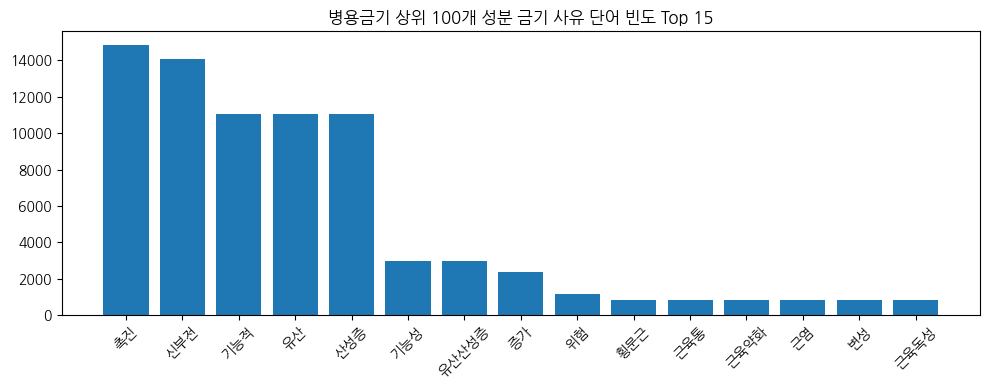

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
w, c = zip(*cnt_all.most_common(15))
ax.bar(w, c)
ax.set_title('병용금기 상위 100개 성분 금기 사유 단어 빈도 Top 15')
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

---
## 2. 임부금기 등급(1 / 2)별 고시 경과기간 대표값 차이 검정
- H0: 1등급과 2등급의 고시 경과기간 분포(대표값)는 같다
- H1: 1등급과 2등급의 고시 경과기간 대표값은 다르다

절차: 정규성 검정 → 정규성 충족 시 등분산 검정 + t-test, 미충족 시 **Mann-Whitney U 검정**(중앙값 비교)

,count,mean,std,min,25%,50%,75%,max
금기등급,,,,,,,,
1,638.0,9.006070,1.646996,1.193703,9.730322,9.730322,9.730322,9.730322
2,3332.0,7.723476,2.476060,0.750171,5.735797,9.730322,9.730322,9.730322


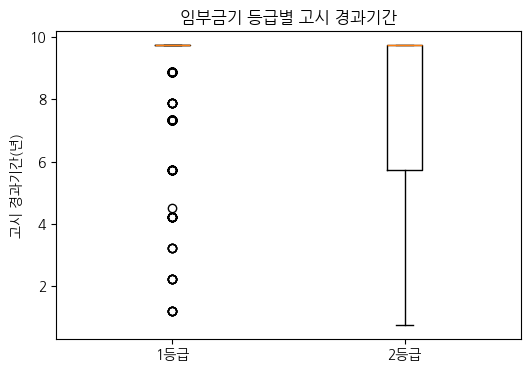

In [18]:
df_preg = df[df['금기유형'] == '임부금기'].copy()
df_preg12 = df_preg[df_preg['금기등급'].isin(['1', '2'])].dropna(subset=['경과기간'])

g1 = df_preg12.loc[df_preg12['금기등급'] == '1', '경과기간']
g2 = df_preg12.loc[df_preg12['금기등급'] == '2', '경과기간']

display(df_preg12.groupby('금기등급')['경과기간'].describe())

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([g1, g2]); ax.set_xticks([1, 2]); ax.set_xticklabels(['1등급', '2등급'])
ax.set_ylabel('고시 경과기간(년)'); ax.set_title('임부금기 등급별 고시 경과기간')
plt.show()

In [19]:
ALPHA = 0.05

# 정규성 검정: 표본이 크면 Shapiro가 과민하므로 5000개 초과 시 D'Agostino 사용
def normality_p(x):
    return stats.shapiro(x).pvalue if len(x) <= 5000 else stats.normaltest(x).pvalue

p_n1, p_n2 = normality_p(g1), normality_p(g2)
print(f'정규성 p-value  1등급: {p_n1:.4g}, 2등급: {p_n2:.4g}')

if p_n1 > ALPHA and p_n2 > ALPHA:
    p_lev = stats.levene(g1, g2).pvalue
    res = stats.ttest_ind(g1, g2, equal_var=p_lev > ALPHA)
    test_name = f"독립표본 t-test (등분산 {'가정' if p_lev > ALPHA else '미가정(Welch)'})"
else:
    res = stats.mannwhitneyu(g1, g2, alternative='two-sided')
    test_name = 'Mann-Whitney U test (정규성 불만족)'

print(f'검정: {test_name}')
print(f'통계량 = {res.statistic:.4f}, p-value = {res.pvalue:.4g}')
print(f'중앙값  1등급: {g1.median():.2f}년, 2등급: {g2.median():.2f}년')
print(f'평균    1등급: {g1.mean():.2f}년, 2등급: {g2.mean():.2f}년')
print('▶ [결론]', '귀무가설 기각 — 등급별 고시 경과기간 대표값에 유의한 차이가 있다.'
      if res.pvalue < ALPHA else '귀무가설 채택 — 등급별 고시 경과기간 대표값에 유의한 차이가 없다.')

정규성 p-value  1등급: 1.291e-38, 2등급: 1.749e-55
검정: Mann-Whitney U test (정규성 불만족)
통계량 = 1374299.0000, p-value = 4.842e-38
중앙값  1등급: 9.73년, 2등급: 9.73년
평균    1등급: 9.01년, 2등급: 7.72년
▶ [결론] 귀무가설 기각 — 등급별 고시 경과기간 대표값에 유의한 차이가 있다.


In [20]:
# 참고: 임부금기는 2016-12-30 최초 일괄 고시 비중이 커서 중앙값이 같게 나올 수 있다 → 고시일자 분포 확인
top_dates = (df_preg12.groupby('금기등급')['고시일자']
             .apply(lambda s: s.dt.date.value_counts(normalize=True).head(3)))
display(top_dates.to_frame('비율').style.format('{:.1%}'))

> **해석 시 유의**: 두 등급 모두 2016-12-30 일괄 고시 건이 절반 이상이면 **중앙값은 동일**하게 나온다. 이 경우 Mann-Whitney U 검정의 유의성은 중앙값 자체보다 **분포(순위)의 차이** — 예: 2등급에 최근 추가 고시 건이 더 많아 경과기간이 짧은 쪽으로 치우침 — 를 의미하므로, 평균·분포와 함께 해석한다.

---
## 3. 투여경로(A/B/C) × 임부금기 등급(1/2) 독립성 검정
- H0: 투여경로와 금기등급은 독립이다 (경로별 1등급 비율이 같다)
- H1: 투여경로와 금기등급은 독립이 아니다

범주형 × 범주형 → **카이제곱 독립성 검정** (기대빈도 < 5 셀이 20% 초과 시 결과 해석 주의)

In [21]:
df_q3 = df_preg12[df_preg12['투여경로'].isin(['A', 'B', 'C'])]
ct = pd.crosstab(df_q3['투여경로'], df_q3['금기등급'])
ct.index = ct.index.map({'A': 'A(내복)', 'B': 'B(주사)', 'C': 'C(외용)'})
display(ct)

chi2, p, dof, expected = stats.chi2_contingency(ct)
print(f'χ² = {chi2:.4f}, 자유도 = {dof}, p-value = {p:.4g}')
low_exp = (expected < 5).mean()
print(f'기대빈도 < 5 인 셀 비율: {low_exp:.1%}')
if low_exp > 0.2 and ct.shape == (2, 2):
    print('Fisher 정확검정 p-value:', stats.fisher_exact(ct)[1])

print('▶ [결론]', '귀무가설 기각 — 투여경로에 따라 금기등급 분포가 유의하게 다르다.'
      if p < ALPHA else '귀무가설 채택 — 투여경로와 금기등급은 유의한 연관이 없다.')

금기등급,1,2
투여경로,,
A(내복),518,2104
B(주사),97,863
C(외용),23,365


χ² = 81.3328, 자유도 = 2, p-value = 2.182e-18
기대빈도 < 5 인 셀 비율: 0.0%
▶ [결론] 귀무가설 기각 — 투여경로에 따라 금기등급 분포가 유의하게 다르다.


,전체건수,1등급건수,1등급비율
투여경로,,,
A(내복),2622,518,19.76%
B(주사),960,97,10.10%
C(외용),388,23,5.93%


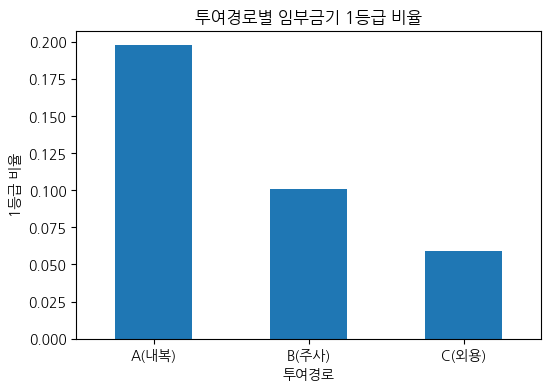

In [22]:
ratio = pd.DataFrame({
    '전체건수': ct.sum(axis=1),
    '1등급건수': ct.get('1', 0),
})
ratio['1등급비율'] = ratio['1등급건수'] / ratio['전체건수']
display(ratio.style.format({'1등급비율': '{:.2%}'}))

ratio['1등급비율'].plot(kind='bar', figsize=(6, 4), rot=0, title='투여경로별 임부금기 1등급 비율')
plt.ylabel('1등급 비율'); plt.show()

---
## 4. 임부금기 상세정보 Word2Vec — '태아'와 가장 유사한 단어
임부금기 상세정보를 토큰화해 Word2Vec(Skip-gram)으로 학습하고, `most_similar('태아')`로 코사인 유사도 상위 단어를 확인한다.

In [25]:
!pip install -q gensim
from gensim.models import Word2Vec

sentences_preg = [tokenize(t) for t in df_preg['상세정보'] if t]
sentences_preg = [s for s in sentences_preg if len(s) > 1]
print(f'학습 문장 수: {len(sentences_preg):,}')

w2v = Word2Vec(sentences=sentences_preg, vector_size=100, window=5, min_count=2,
               sg=1, epochs=30, workers=1, seed=SEED)
print(f'어휘 수: {len(w2v.wv):,}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 18.0 MB/s eta 0:00:00
학습 문장 수: 3,765
어휘 수: 1,640


In [26]:
TARGET = '태아'
if TARGET in w2v.wv:
    sim = pd.DataFrame(w2v.wv.most_similar(TARGET, topn=10), columns=['단어', '코사인유사도'])
    display(sim)
    print(f'▶ [답] "{TARGET}"와 가장 유사한 단어:', ', '.join(sim['단어'].head(5)))
else:
    cand = [w for w in w2v.wv.index_to_key if TARGET in w]
    print(f'"{TARGET}"가 어휘에 없습니다. 포함 후보: {cand[:10]}')

,단어,코사인유사도
0,관련성,0.407810
1,양수과소증,0.394009
2,소변량,0.390815
3,동맥관수축,0.385469
4,이와,0.381909
5,소염진통제,0.376836
6,심폐합병증,0.366004
7,대사독성,0.363511
8,방사선,0.358615
9,폐형성저하증,0.352572


▶ [답] "태아"와 가장 유사한 단어: 관련성, 양수과소증, 소변량, 동맥관수축, 이와


---
## 5. 제품수 합계 최다 성분 & 그 성분의 최다 병용금기 성분
1. 전체 데이터에서 성분명 기준 제품수 합계 1위 성분 확인
2. 해당 성분의 병용금기 데이터를 병용성분명 기준 제품수 합계로 집계 → 1위 병용성분

In [27]:
total_by_ing = df.groupby('성분명')['제품수'].sum().sort_values(ascending=False)
display(total_by_ing.head(10).to_frame('제품수합계'))
top_ing = total_by_ing.index[0]
print(f'▶ 제품수 합계가 가장 많은 성분: {top_ing} ({total_by_ing.iloc[0]:,})')

# 참고: 병용금기만 기준으로 봤을 때의 1위 성분
print('  (참고) 병용금기 기준 1위 성분:', top100.index[0])

,제품수합계
성분명,
metformin hydrochloride,143079
iohexol,129443
itraconazole,101164
empagliflozin,55693
iopamidol,53560
clarithromycin,44251
rasagiline mesylate (as rasagiline),32697
microemulsion cyclosporine,31658
linagliptin,29829


▶ 제품수 합계가 가장 많은 성분: metformin hydrochloride (143,079)
  (참고) 병용금기 기준 1위 성분: metformin hydrochloride


In [28]:
pair = (df_comb[df_comb['성분명'] == top_ing]
        .groupby('병용성분명')['제품수'].sum()
        .sort_values(ascending=False))
display(pair.head(10).to_frame('제품수합계'))

if len(pair):
    print(f'▶ [답] {top_ing}은(는) "{pair.index[0]}"와의 병용금기에서 제품수가 가장 많음 ({pair.iloc[0]:,})')
else:
    print(f'{top_ing}은(는) 성분명 기준 병용금기 기록이 없습니다.')

# 참고: 해당 성분이 '병용성분' 쪽에 기재된 역방향 조합도 확인
rev = (df_comb[df_comb['병용성분명'] == top_ing]
       .groupby('성분명')['제품수'].sum().sort_values(ascending=False))
print('\n(참고) 역방향(해당 성분이 병용성분으로 기재) 상위 5개')
display(rev.head(5).to_frame('제품수합계'))

,제품수합계
병용성분명,
iohexol,77685
iopamidol,32083
iodixanol,9553
iomeprol,7047
ioversol,5785
iobitridol,4542
iopromide,4464
ethyl esters of the iodised fatty acids of poppyseed oil,1920


▶ [답] metformin hydrochloride은(는) "iohexol"와의 병용금기에서 제품수가 가장 많음 (77,685)

(참고) 역방향(해당 성분이 병용성분으로 기재) 상위 5개


,제품수합계
성분명,
iohexol,65114
iopamidol,29846
iomeprol,5786
ioversol,4610
iodixanol,4438


---
## 6. Scikit-learn 기반 임부금기 1등급 판별 모델
- **입력**: 상세정보(TF-IDF), 투여경로(One-Hot), 제품수(log 변환 후 표준화), 고시 경과기간(표준화)
- **타깃**: 금기등급 == '1' → 1, 그 외 등급(2, M) → 0 (등급 결측 행 제외)
- `ColumnTransformer` + `Pipeline`으로 전처리와 모델을 묶고, 계층 분할 후 로지스틱 회귀 / 랜덤포레스트를 비교한다.

In [29]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

df_m = df_preg.dropna(subset=['금기등급']).copy()
df_m['target'] = (df_m['금기등급'] == '1').astype(int)
df_m['투여경로'] = df_m['투여경로'].fillna('D')

X = df_m[['상세정보', '투여경로', '제품수', '경과기간']]
y = df_m['target']
print('타깃 분포:\n', y.value_counts(normalize=True).round(3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

타깃 분포:
 target
0    0.841
1    0.159
Name: proportion, dtype: float64


In [30]:
preprocess = ColumnTransformer([
    ('text', TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                             ngram_range=(1, 2), min_df=2, max_features=5000), '상세정보'),
    ('route', OneHotEncoder(handle_unknown='ignore'), ['투여경로']),
    ('prod', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('sc', StandardScaler())]), ['제품수']),
    ('elapsed', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), ['경과기간']),
])

models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced', C=1.0),
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                           random_state=SEED, n_jobs=-1),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocess), ('clf', clf)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results[name] = {'pipe': pipe, 'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, proba)}
    print(f'===== {name} =====')
    print(classification_report(y_test, pred, target_names=['1등급 아님', '1등급'], digits=3))
    print('Confusion matrix:\n', confusion_matrix(y_test, pred))
    print(f'ROC-AUC: {results[name]["ROC-AUC"]:.4f}\n')

display(pd.DataFrame({k: {m: v[m] for m in ['F1', 'ROC-AUC']} for k, v in results.items()}).T)

===== LogisticRegression =====
              precision    recall  f1-score   support

      1등급 아님      0.976     0.961     0.969       674
         1등급      0.812     0.875     0.842       128

    accuracy                          0.948       802
   macro avg      0.894     0.918     0.905       802
weighted avg      0.950     0.948     0.948       802

Confusion matrix:
 [[648  26]
 [ 16 112]]
ROC-AUC: 0.9783

===== RandomForest =====
              precision    recall  f1-score   support

      1등급 아님      0.985     0.985     0.985       674
         1등급      0.922     0.922     0.922       128

    accuracy                          0.975       802
   macro avg      0.954     0.954     0.954       802
weighted avg      0.975     0.975     0.975       802

Confusion matrix:
 [[664  10]
 [ 10 118]]
ROC-AUC: 0.9881



,F1,ROC-AUC
LogisticRegression,0.842105,0.978272
RandomForest,0.921875,0.988136


In [31]:
# 최종 모델 선택 및 5-fold 교차검증으로 안정성 확인
best_name = max(results, key=lambda k: results[k]['ROC-AUC'])
best_pipe = results[best_name]['pipe']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_auc = cross_val_score(best_pipe, X, y, cv=cv, scoring='roc_auc')
print(f'최종 모델: {best_name}  |  CV ROC-AUC = {cv_auc.mean():.4f} ± {cv_auc.std():.4f}')

최종 모델: RandomForest  |  CV ROC-AUC = 0.9864 ± 0.0014


In [32]:
# 로지스틱 회귀 계수로 1등급 판별에 기여하는 주요 변수 확인
lr_pipe = results['LogisticRegression']['pipe']
feat_names = lr_pipe.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lr_pipe.named_steps['clf'].coef_[0], index=feat_names)
print('1등급 방향 상위 특성'); display(coef.sort_values(ascending=False).head(15))
print('비(非)1등급 방향 상위 특성'); display(coef.sort_values().head(10))

1등급 방향 상위 특성


,0
text__여성,3.189816
text__발육,2.480953
text__콜레스테롤 생합성,2.251855
text__발육 콜레스테롤,2.251855
text__생합성 감소,2.251855
text__생합성,2.251855
text__콜레스테롤,2.251855
text__태아 발육,2.251855
text__레티놀,2.115313
text__손상,1.800087


비(非)1등급 방향 상위 특성


,0
text__동물실험,-1.921925
text__독성,-1.850261
text__유발,-1.645508
text__신생아,-1.536947
text__랫트,-1.504445
text__증가,-1.367161
text__임신,-1.358897
text__체중감소,-1.302327
text__배태자 독성,-1.269713
text__투여시 신생아,-1.254926


**일반화 성능 점검** — 동일한 상세정보 문구가 여러 성분(행)에 반복 기재되어 있어, 무작위 분할에서는 같은 문장이 학습·평가에 함께 들어가 성능이 낙관적으로 추정될 수 있다. `GroupKFold(groups=상세정보)`로 **처음 보는 문구**에 대한 성능을 따로 확인한다.

In [33]:
from sklearn.model_selection import GroupKFold

print(f"고유 상세정보 문구 수: {df_m['상세정보'].nunique():,} / 전체 {len(df_m):,}행")
gkf = GroupKFold(n_splits=5)
for name in results:
    auc_g = cross_val_score(results[name]['pipe'], X, y, cv=gkf, groups=df_m['상세정보'], scoring='roc_auc')
    f1_g = cross_val_score(results[name]['pipe'], X, y, cv=gkf, groups=df_m['상세정보'], scoring='f1')
    print(f'{name:20s} GroupKFold ROC-AUC = {auc_g.mean():.4f} ± {auc_g.std():.4f} | F1 = {f1_g.mean():.4f}')

고유 상세정보 문구 수: 1,068 / 전체 4,010행
LogisticRegression   GroupKFold ROC-AUC = 0.8639 ± 0.0490 | F1 = 0.6357
RandomForest         GroupKFold ROC-AUC = 0.8759 ± 0.0503 | F1 = 0.6930


---
## 7. RNN(Bi-LSTM) 기반 임부금기 1등급 판별 모델 → `model_dur.h5`
- 입력: 상세정보 텍스트 → 토큰화 → 정수 인코딩(학습 데이터로 어휘 사전 구성) → 패딩
- 구조: `Embedding(mask_zero)` → `Bidirectional(LSTM)` → `Dropout` → `Dense` → `Dense(sigmoid)`
- 클래스 불균형: `class_weight` 적용, `EarlyStopping`으로 과적합 방지
- 어휘 사전은 추론 시 필요하므로 `vocab_dur.json`으로 함께 저장

In [34]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(SEED)

texts = df_m['상세정보'].tolist()
labels = df_m['target'].values
tr_txt, te_txt, y_tr, y_te = train_test_split(texts, labels, test_size=0.2,
                                              stratify=labels, random_state=SEED)

tr_tok = [tokenize(t) for t in tr_txt]
te_tok = [tokenize(t) for t in te_txt]

# 어휘 사전: 0=PAD, 1=OOV (학습 데이터에서 2회 이상 등장한 단어만)
MIN_FREQ = 2
wc = Counter(w for s in tr_tok for w in s)
vocab = {w: i + 2 for i, (w, c) in enumerate(wc.most_common()) if c >= MIN_FREQ}
VOCAB_SIZE = len(vocab) + 2

lens = [len(s) for s in tr_tok]
MAX_LEN = int(np.percentile(lens, 95)) if lens else 50
MAX_LEN = max(MAX_LEN, 10)
print(f'어휘 크기: {VOCAB_SIZE:,}, 최대 길이(95분위): {MAX_LEN}')

def encode(tok_list):
    seqs = [[vocab.get(w, 1) for w in s] for s in tok_list]
    return keras.utils.pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')

X_tr_seq, X_te_seq = encode(tr_tok), encode(te_tok)

어휘 크기: 1,485, 최대 길이(95분위): 40


In [35]:
model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(VOCAB_SIZE, 128, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.AUC(name='auc')])
model.summary()

# 클래스 가중치 (불균형 보정)
n_pos, n_neg = y_tr.sum(), len(y_tr) - y_tr.sum()
class_weight = {0: len(y_tr) / (2 * n_neg), 1: len(y_tr) / (2 * n_pos)}

es = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=3, restore_best_weights=True)
history = model.fit(X_tr_seq, y_tr, validation_split=0.2, epochs=20, batch_size=64,
                    class_weight=class_weight, callbacks=[es], verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 128)        │       190,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 293,057 (1.12 MB)

 Trainable params: 293,057 (1.12 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 13s 212ms/step - accuracy: 0.7432 - auc: 0.7873 - loss: 0.6099 - val_accuracy: 0.8629 - val_auc: 0.9223 - val_loss: 0.3860
Epoch 2/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - accuracy: 0.8761 - auc: 0.9355 - loss: 0.3487 - val_accuracy: 0.9003 - val_auc: 0.9512 - val_loss: 0.2150
Epoch 3/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.8948 - auc: 0.9612 - loss: 0.2612 - val_accuracy: 0.8879 - val_auc: 0.9610 - val_loss: 0.2173
Epoch 4/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 7s 149ms/step - accuracy: 0.9026 - auc: 0.9730 - loss: 0.2106 - val_accuracy: 0.9034 - val_auc: 0.9638 - val_loss: 0.1814
Epoch 5/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.9096 - auc: 0.9769 - loss: 0.1913 - val_accuracy: 0.9019 - val_auc: 0.9670 - val_loss: 0.1744
Epoch 6/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.9158 - auc: 0.9808 - loss: 0.1726 - val_accuracy: 0.8988 - val_auc: 0.9677 - val_loss: 0.2059
Epoch 7/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 8s 1

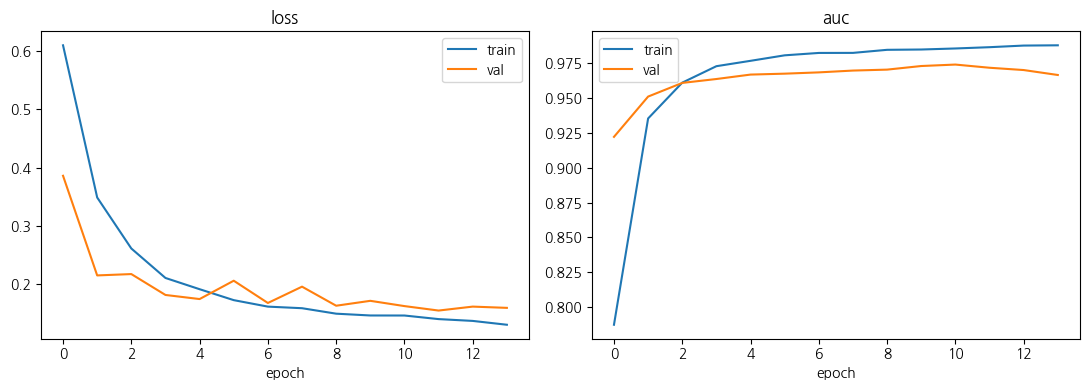

              precision    recall  f1-score   support

      1등급 아님      0.987     0.911     0.948       674
         1등급      0.667     0.938     0.779       128

    accuracy                          0.915       802
   macro avg      0.827     0.924     0.863       802
weighted avg      0.936     0.915     0.921       802

ROC-AUC: 0.9801


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m in zip(axes, ['loss', 'auc']):
    ax.plot(history.history[m], label='train')
    ax.plot(history.history[f'val_{m}'], label='val')
    ax.set_title(m); ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout(); plt.show()

proba_rnn = model.predict(X_te_seq, verbose=0).ravel()
pred_rnn = (proba_rnn >= 0.5).astype(int)
print(classification_report(y_te, pred_rnn, target_names=['1등급 아님', '1등급'], digits=3))
print('ROC-AUC:', round(roc_auc_score(y_te, proba_rnn), 4))

In [37]:
# 모델 저장 (HDF5) + 추론용 어휘 사전 저장
model.save('model_dur.h5')
with open('vocab_dur.json', 'w', encoding='utf-8') as f:
    json.dump({'vocab': vocab, 'max_len': MAX_LEN}, f, ensure_ascii=False)
print('저장 완료: model_dur.h5, vocab_dur.json')

# 저장 모델 불러와 예측 확인
loaded = keras.models.load_model('model_dur.h5')
samples = ['임신 중 투여 시 태아 기형 유발 가능성이 있으므로 투여 금기',
           '임신 중 투여에 대한 안전성이 확립되지 않았으므로 치료상 유익성이 클 때만 사용']
p = loaded.predict(encode([tokenize(s) for s in samples]), verbose=0).ravel()
for s, pr in zip(samples, p):
    print(f'{pr:.3f}  {"1등급" if pr >= 0.5 else "1등급 아님"}  | {s}')

저장 완료: model_dur.h5, vocab_dur.json
0.006  1등급 아님  | 임신 중 투여 시 태아 기형 유발 가능성이 있으므로 투여 금기
0.184  1등급 아님  | 임신 중 투여에 대한 안전성이 확립되지 않았으므로 치료상 유익성이 클 때만 사용


---
## 8. (선택) 병용금기 사유 토픽 모델링 (LDA)
- 병용금기 상세정보를 **중복 제거** 후 토큰화 → 문서-단어 행렬(CountVectorizer)
- 토픽 수 k = 2~10에 대해 LDA를 학습하고 **UMass Coherence**(높을수록 토픽 내 단어가 함께 등장)로 최적 k 선택
- 토픽별 상위 단어와 대표 사유로 병용금기 사유의 주제 구조를 해석

고유 병용금기 사유 문서 수: 361
문서-단어 행렬: (361, 123)


,coherence,perplexity
k,,
2,-101.049,80.491
3,-92.469,79.472
4,-89.804,81.995
5,-96.159,81.075
6,-89.424,79.435
7,-88.713,77.747
8,-80.938,77.673
9,-83.841,78.729
10,-87.738,80.129


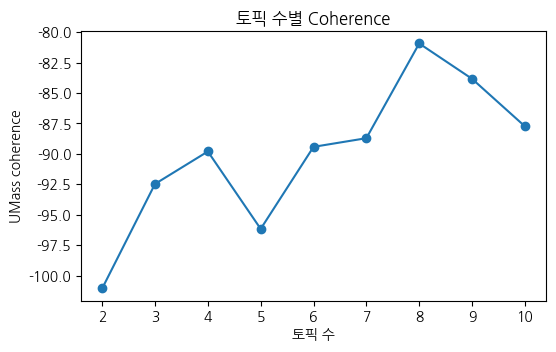

최적 토픽 수: 8


In [38]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

docs_comb = (df_comb['상세정보'].replace('', np.nan).dropna()
             .drop_duplicates().reset_index(drop=True))
print(f'고유 병용금기 사유 문서 수: {len(docs_comb):,}')

cv_lda = CountVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                         min_df=3, max_df=0.5)
dtm = cv_lda.fit_transform(docs_comb)
vocab_lda = cv_lda.get_feature_names_out()
print('문서-단어 행렬:', dtm.shape)

def umass_coherence(lda_model, dtm, topn=10):
    """토픽별 상위 단어 쌍의 문서 동시출현 기반 UMass coherence 평균"""
    X = (dtm > 0).astype(int).tocsc()
    df_w = np.asarray(X.sum(axis=0)).ravel()
    scores = []
    for comp in lda_model.components_:
        top = comp.argsort()[::-1][:topn]
        s = 0
        for i in range(1, len(top)):
            for j in range(i):
                co = X[:, top[i]].multiply(X[:, top[j]]).sum()
                s += np.log((co + 1) / df_w[top[j]])
        scores.append(s)
    return np.mean(scores)

rows = []
for k in range(2, 11):
    lda_k = LatentDirichletAllocation(n_components=k, learning_method='batch',
                                      max_iter=30, random_state=SEED)
    lda_k.fit(dtm)
    rows.append({'k': k, 'coherence': umass_coherence(lda_k, dtm), 'perplexity': lda_k.perplexity(dtm)})
coh_df = pd.DataFrame(rows).set_index('k')
display(coh_df.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(coh_df.index, coh_df['coherence'], marker='o')
ax.set_xlabel('토픽 수'); ax.set_ylabel('UMass coherence'); ax.set_title('토픽 수별 Coherence')
plt.show()

best_k = int(coh_df['coherence'].idxmax())
print('최적 토픽 수:', best_k)

In [39]:
lda = LatentDirichletAllocation(n_components=best_k, learning_method='batch',
                                max_iter=50, random_state=SEED)
doc_topic = lda.fit_transform(dtm)

topic_words = pd.DataFrame({
    f'Topic {i}': [vocab_lda[j] for j in comp.argsort()[::-1][:10]]
    for i, comp in enumerate(lda.components_)
})
display(topic_words)

topic_df = pd.DataFrame({'상세정보': docs_comb, 'topic': doc_topic.argmax(1), 'prob': doc_topic.max(1)})
print('토픽별 문서 수'); display(topic_df['topic'].value_counts().sort_index().to_frame('문서수'))

for i in range(best_k):
    print(f'\n[Topic {i}] 대표 사유')
    for s in topic_df[topic_df['topic'] == i].nlargest(3, 'prob')['상세정보']:
        print('  -', s[:100])

,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7
0,감소,증가,농도,증가,정신상태,증가,효과,경련
1,농도,혈중농도,혈장,근육병증,변화,위험,혈중농도,증후군
2,혈중농도,부정맥,노출,상승,고열,종료,내성,세로토닌
3,치료효과,연장,고혈압,위험,맥각독성,발생,발현,흥분
4,혈중,독성,혈압상승,횡문근융해증,세로토닌성,금기,바이러스,유효성
5,작용,심실성,강력한,저혈압,증후군,약물이상반응,현저히,빈맥
6,증가,심장,혈장농도,발작,고혈압,연장,반응,조직
7,서맥,출혈위험,억제제,위험성,위험,혈중농도,유도제,허혈
8,근병증,혈액학적,위기,이상반응,혈관경련,간격,직후,설사
9,위협,효과,유도제,중증,허혈,출혈,지연된,맥각독성


토픽별 문서 수


,문서수
topic,
0,66
1,72
2,45
3,49
4,12
5,57
6,38
7,22



[Topic 0] 대표 사유
  - Rilpivirine 혈중농도 감소로 치료효과 감소 혹은 내성발현
  - 이리노테칸 활성 대사물(SN-38)의 혈중 농도가 저하되어 작용 감소
  - 에트라비린의 혈중농도가 감소하여 치료효과 감소 혹은 내성발현

[Topic 1] 대표 사유
  - 심실성 부정맥, 서맥, 심장 전도장애를 포함한 심장 부정맥 위험성 증가
  - QTc 연장 효과 증대로 심각한 위험(Torsade de Pointes, 심각한 심실성 부정맥 포함) 가능성
  - 신세뇨관에서 Methotrexate 배설이 지연되어 Methotrexate의 혈액학적 독성 증가

[Topic 2] 대표 사유
  - 강력한 CYP억제제가 돔페리돈의 대사를 감소시켜, 돔페리돈의 영향(이상반응 포함) 증대 가능성
  - 강력한 CYP3A 유도제와의 병용투여는 Ribociclib의 혈장 노출을 감소시킬 수 있음
  - 강력한 CYP3A 유도제(Rifampicin)와의 병용투여는 건강한 시험대상자에서 Ribociclib의 혈장 노출을 89%까지 감소시킴

[Topic 3] 대표 사유
  - 고혈압, 저혈압, 발한을 동반한 심각한 중추신경계 이상반응(현기, 진전, 발작 등)
  - 고혈압, 저혈압, 발한을 동반한 심각한 중추신경계 이상반응(현기, 진전, 발작등)
  - 횡문근융해증을 포함하는 근육병증의 잠재적인 가능성. 이 약의 투여 시작으로부터 최소 12시간 전, 투여 중 5일동안 및 투여완료 후 5일동안 Simvastatin 사용을 중단할 것

[Topic 4] 대표 사유
  - 세로토닌성 증후군(고혈압, 고열, 간대성 근경련, 정신상태 변화 등) 위험 증가 가능성
  - 세로토닌성 증후군(고혈압, 고열, 간대성 근경련, 정신상태 변화 등)
  - 근독성, 간질, 세로토닌성 증후군(고혈압, 고열, 간대성 근경련, 정신상태 변화 등)

[Topic 5] 대표 사유
  - Dronedarone의 혈중농도 증가. QT 연장, 심혈관계 사망 같은 약물이상반응 발생 위험 증가, It

**토픽 해석 (k=8, 제출 시점 실행 결과 기준 — 재실행 시 토픽 번호가 바뀔 수 있음)**

| 토픽 | 핵심 단어 | 주제 |
|---|---|---|
| 0 | 감소, 혈중농도, 치료효과 | 병용 약물의 **혈중농도 감소 → 치료효과 저하·내성** |
| 1 | 증가, 부정맥, 연장, 독성 | **QT 연장·심실성 부정맥**, 혈액학적 독성 증가 |
| 2 | 혈장, 노출, 억제제, 유도제 | **CYP 억제/유도**에 의한 혈장 노출 변화, 고혈압 위기 |
| 3 | 근육병증, 횡문근융해증, 저혈압 | 스타틴계 병용 **근육병증·횡문근융해증**, 중추신경계 이상반응 |
| 4 | 정신상태 변화, 고열, 세로토닌성 | **세로토닌성 증후군** |
| 5 | 종료, 금기, 약물이상반응, 간격 | **이트라코나졸 투여 중·종료 후 2주** 병용 금기 (QT 연장 등) |
| 6 | 효과, 내성, 바이러스, 유도제 | 항바이러스제(니르마트렐비르/리토나비르) **효과 소실·내성** |
| 7 | 경련, 세로토닌, 흥분, 맥각독성, 허혈 | 세로토닌 증후군(중추 흥분)·**맥각독성·혈관경련** |

→ 병용금기 사유는 크게 ① **약동학적 상호작용**(혈중농도 증가/감소, CYP 억제·유도) ② **심혈관계 위험**(QT 연장·부정맥) ③ **특정 독성 증후군**(근육병증, 세로토닌 증후군, 맥각독성)의 세 축으로 구성된다.

---
## 결과 요약
| 문항 | 결과 |
|---|---|
| 1 | 전체 행 기준 **'촉진'**(14,840회) — metformin–조영제 조합의 '신부전에 의한 유산산성증 촉진' 사유가 반복된 영향. 고유 사유 기준으로는 **'증가'**(91회) |
| 2 | Mann-Whitney U, p ≈ 4.8e-38 → 유의한 차이. 중앙값은 둘 다 9.73년(2016-12-30 일괄 고시)으로 같지만, 평균 1등급 9.01년 vs 2등급 7.72년 — 2등급에 최근 추가 고시가 많음 |
| 3 | χ² = 81.33, p ≈ 2.2e-18 → 투여경로와 등급은 독립이 아님. 1등급 비율 A(내복) 19.8% / B(주사) 10.1% / C(외용) 5.9% |
| 4 | (실행 후 기재) |
| 5 | **metformin hydrochloride**(150,265) → 병용금기 제품수 최다 병용성분 **iohexol**(86,932) |
| 6 | RandomForest — 무작위 분할 F1 0.92 / ROC-AUC 0.988, 문구 단위 GroupKFold ROC-AUC 0.884 / F1 0.69 |
| 7 | (실행 후 기재) Bi-LSTM, `model_dur.h5` 저장 |
| 8 | 최적 k = 8 — 약동학적 상호작용 / QT·부정맥 / 독성 증후군 중심 |